# Pipeline: comparison, ensemble, temporal post-processing, failure cases

Runs locally on the saved outputs of `02_ultralytics` and `03_torchvision` (`val_predictions.json`, `submission.csv`, `results.csv` of every run in `runs/<run_id>/`); no model is re-run. Every step is scored on all 2,846 validation frames with the same evaluator, and a step is kept only if it raises validation mAP. The final section rebuilds the two submitted files.

In [1]:
import gc
import json
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MaxNLocator
from PIL import Image

ROOT = Path.cwd() if Path("src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import index_annotations, load, select_frames
from src.ensemble import EMPTY, box_iou, fuse, read_test, read_val, rescore
from src.evaluate import evaluate
from src.submission import write_submission

DATA = ROOT / "data/raw"
RUNS = ROOT / "runs"
RESULTS = ROOT / "results"
FIGURES = ROOT / "images"
OUT = RUNS / "local/submissions"
OUT.mkdir(parents=True, exist_ok=True)
FAMILIES = {"yolo": "YOLO11", "frcnn": "Faster R-CNN", "retina": "RetinaNet", "rtdetr": "RT-DETR-l"}
COLORS = {"YOLO11": "#2a78d6", "Faster R-CNN": "#eb6834", "RetinaNet": "#1baf7a", "RT-DETR-l": "#eda100"}
family = lambda run: next(name for prefix, name in FAMILIES.items() if run.startswith(prefix))

val_coco = load(DATA / "val/annotations_coco.json")
test = pd.read_csv(DATA / "test_images.csv")
names = {c["id"] - 1: c["name"] for c in val_coco["categories"]}
val_size = {i["id"]: (i["width"], i["height"]) for i in val_coco["images"]}
test_size = {r.image_id: (r.width, r.height) for r in test.itertuples()}
val_clips = defaultdict(list)
for image in select_frames(val_coco):  # ordered by frame within each clip
    val_clips[image["video"]].append(image["id"])
test_clips = [g.sort_values("frame").image_id.tolist() for _, g in test.groupby("clip")]
print(len(val_size), "val frames in", len(val_clips), "clips |", len(test_size), "test frames in", len(test_clips), "clips")

2846 val frames in 7 clips | 3811 test frames in 48 clips


## All runs

Every completed run from `results/experiments.csv`, scored on all validation frames with the best checkpoint of its training curve. The five fold runs are left out: each is scored on its own held-out clips, not on the validation split.

In [2]:
runs = pd.read_csv(RESULTS / "experiments.csv").query("status == 'completed'")
runs = runs[~runs.run_id.str.contains("fold")].copy()
runs["family"] = runs.run_id.map(family)
runs = runs.sort_values(["family", "mAP"])
runs[["run_id", "epochs", "imgsz", "train_stride", "mAP", "AP50", "AP_small", "AP_medium", "AP_large", "gpu_hours", "public_lb"]].round(4)

,run_id,epochs,imgsz,train_stride,mAP,AP50,AP_small,AP_medium,AP_large,gpu_hours,public_lb
13,frcnn_1280_5ep_prop3000,5,1280,5,0.2169,0.4540,0.1099,0.2086,0.3785,1.347,NaN
11,frcnn_1280_5ep_anchor16,5,1280,5,0.2225,0.4670,0.1066,0.2060,0.4026,1.259,NaN
8,frcnn_1280_5ep,5,1280,5,0.2252,0.4502,0.1063,0.2130,0.3915,1.151,NaN
28,frcnn_1280_2ep_anchor16_tile960,2,1280,10,0.2499,0.5168,0.1228,0.2443,0.3931,1.562,NaN
6,rtdetr-l_960_10ep,10,960,5,0.1253,0.2524,0.0518,0.1131,0.2356,1.218,NaN
18,rtdetr-l_960_10ep_lr0002,10,960,5,0.1732,0.3484,0.0823,0.1611,0.2741,1.236,NaN
19,rtdetr-l_960_20ep_lr0002,20,960,5,0.1905,0.3674,0.0892,0.1722,0.3154,2.336,NaN
12,retina_1280_5ep_anchor16,5,1280,5,0.1520,0.3288,0.0584,0.1370,0.2845,0.916,NaN
9,retina_1280_5ep,5,1280,5,0.1645,0.3191,0.0589,0.1481,0.3180,0.953,NaN
14,retina_1280_5ep_gamma1,5,1280,5,0.1688,0.3225,0.0624,0.1510,0.3294,0.876,NaN


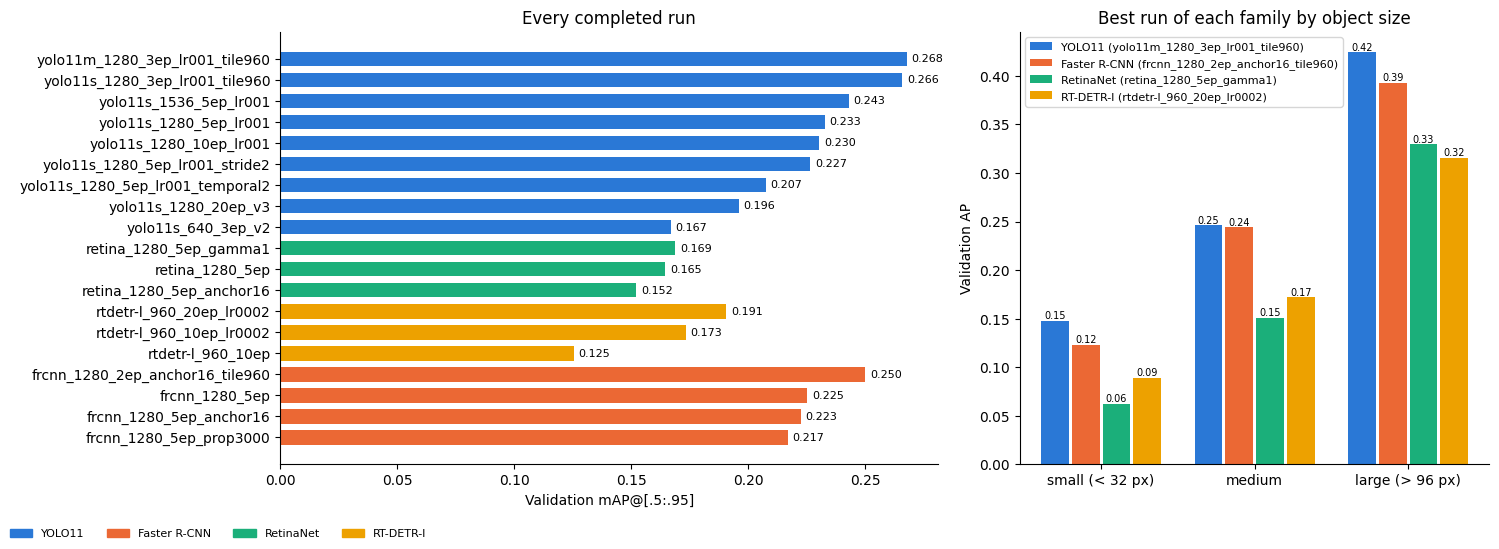

In [3]:
best = runs.loc[runs.groupby("family").mAP.idxmax()].set_index("family").loc[list(COLORS)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].barh(runs.run_id, runs.mAP, color=runs.family.map(COLORS), height=0.7)
for y, v in enumerate(runs.mAP):
    axes[0].text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8)
axes[0].set_xlabel("Validation mAP@[.5:.95]")
axes[0].set_title("Every completed run")
x = np.arange(3)
for k, (name, row) in enumerate(best.iterrows()):
    bars = axes[1].bar(x + (k - 1.5) * 0.2, row[["AP_small", "AP_medium", "AP_large"]].astype(float), 0.18, color=COLORS[name], label=f"{name} ({row.run_id})")
    axes[1].bar_label(bars, fmt="%.2f", fontsize=7)
axes[1].set_xticks(x, ["small (< 32 px)", "medium", "large (> 96 px)"])
axes[1].set_ylabel("Validation AP")
axes[1].set_title("Best run of each family by object size")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.legend(handles=[Patch(color=c, label=n) for n, c in COLORS.items()], loc="lower left", ncol=4, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIGURES / "model_comparison.png", dpi=160)
plt.show()

## Training curves

mAP after every epoch on every 10th validation frame, the curve that picked `best.pt`. Ultralytics computes it with its own validator on the exported frames; the torchvision loop uses `src/evaluate.py`. The values are comparable within a family, not across families.

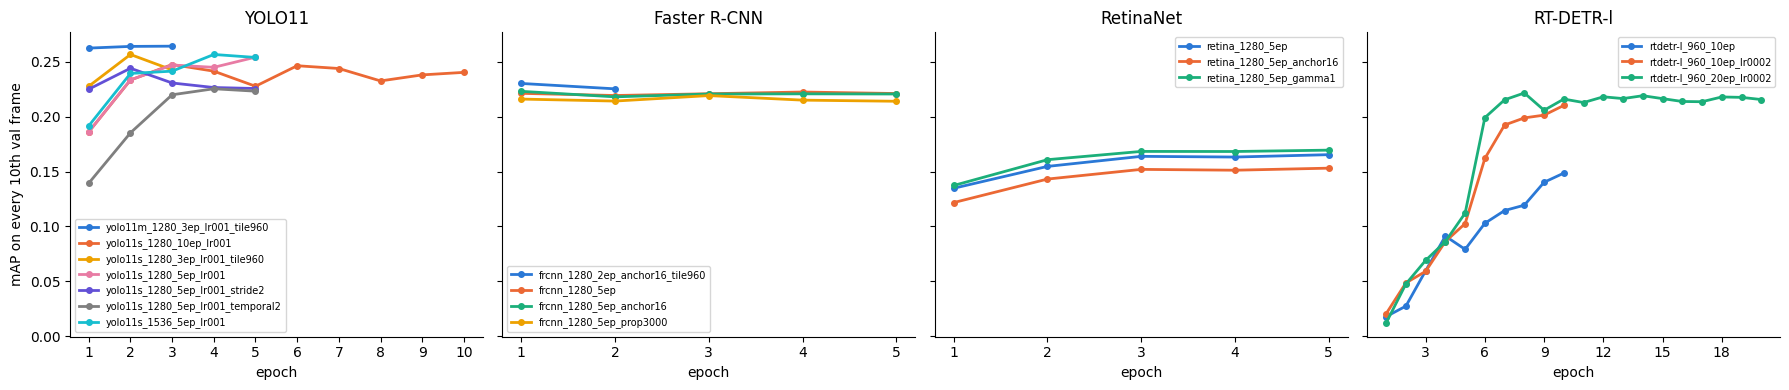

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6", "#7f7f7f", "#17becf"]
for ax, name in zip(axes, COLORS):
    for color, run in zip(palette, runs.query("family == @name").sort_values("run_id").run_id):
        path = RUNS / run / run / "results.csv"
        if path.exists():
            curve = pd.read_csv(path).rename(columns=str.strip)
            ax.plot(curve.epoch, curve.get("metrics/mAP50-95(B)", curve.get("mAP")), "o-", ms=4, lw=2, color=color, label=run)
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=7)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("mAP on every 10th val frame")
fig.tight_layout()
fig.savefig(FIGURES / "val_curves.png", dpi=160)
plt.show()

## Saved predictions

Validation predictions come from `val_predictions.json` (COCO format), test predictions from `submission.csv`; `src/ensemble.py` reads both into numpy arrays per image. Both hold up to 500 boxes per image with scores down to 0.001; boxes narrower or lower than 1 px are dropped, as in `predict_yolo`.

Members: the best runs of `02_ultralytics` and `03_torchvision`, plus the three runs trained on 960 px crops ("tile": YOLO11s, YOLO11m and Faster R-CNN anchor16, predicted on the whole frame plus its crops).

In [5]:
Y1, Y2 = "yolo11s_1280_5ep_lr001", "yolo11s_1536_5ep_lr001"
F1, F2 = "frcnn_1280_5ep", "frcnn_1280_5ep_anchor16"
RETINA, DETR, TEMPORAL = "retina_1280_5ep_gamma1", "rtdetr-l_960_20ep_lr0002", "yolo11s_1280_5ep_lr001_temporal2"
TS, TM, TF = "yolo11s_1280_3ep_lr001_tile960", "yolo11m_1280_3ep_lr001_tile960", "frcnn_1280_2ep_anchor16_tile960"
val_dets = {run: read_val(RUNS / run / "val_predictions.json") for run in [Y1, Y2, F1, F2, RETINA, DETR, TEMPORAL, TS, TM, TF]}
steps = [{"step": run, **evaluate(val_coco, dets)} for run, dets in val_dets.items()]
pd.DataFrame(steps).round(4)

,step,mAP,AP50,AP_small,AP_medium,AP_large
0,yolo11s_1280_5ep_lr001,0.2327,0.4425,0.1251,0.2248,0.3910
1,yolo11s_1536_5ep_lr001,0.2430,0.4630,0.1207,0.2429,0.3729
2,frcnn_1280_5ep,0.2252,0.4502,0.1063,0.2130,0.3915
3,frcnn_1280_5ep_anchor16,0.2225,0.4670,0.1066,0.2060,0.4026
4,retina_1280_5ep_gamma1,0.1688,0.3225,0.0624,0.1510,0.3294
5,rtdetr-l_960_20ep_lr0002,0.1905,0.3674,0.0892,0.1722,0.3154
6,yolo11s_1280_5ep_lr001_temporal2,0.2075,0.3963,0.1123,0.1986,0.3330
7,yolo11s_1280_3ep_lr001_tile960,0.2657,0.5064,0.1550,0.2503,0.4344
8,yolo11m_1280_3ep_lr001_tile960,0.2676,0.5223,0.1477,0.2463,0.4241
9,frcnn_1280_2ep_anchor16_tile960,0.2499,0.5168,0.1228,0.2443,0.3931


## Ensemble: weighted boxes fusion

[Weighted boxes fusion](https://arxiv.org/abs/1910.13302) clusters same-class boxes from several models by IoU and replaces each cluster with a score-weighted average box. Unlike NMS it keeps information from every model, and a box found by only one of N models has its score scaled by 1/N. YOLO and Faster R-CNN make different mistakes (one-stage dense grid vs proposals and RoI pooling), so they are fused first; the fusion IoU is chosen on that mix and kept for every later step.

Blends are listed in the order they were built. "2 YOLO" is YOLO11s at 1280 and 1536 px, "2 FRCNN" the Faster R-CNN baseline and anchor16, "tile s / tile m / tile FRCNN" the runs trained on crops, and "x2" a fusion weight of 2.

In [6]:
for iou in [0.6, 0.7, 0.8]:
    steps.append({"step": f"2 YOLO + FRCNN, IoU {iou}", **evaluate(val_coco, fuse([val_dets[r] for r in [Y1, Y2, F1]], val_size, None, iou))})
FUSE_IOU = float(max(steps[-3:], key=lambda s: s["mAP"])["step"].split()[-1])

def blend(members, size=val_size, dets=val_dets):
    # members: {run: fusion weight}
    return fuse([dets[r] for r in members], size, list(members.values()), FUSE_IOU)

BASE = {Y1: 1, Y2: 1, F1: 1, F2: 1}
TILE = {TS: 2, TM: 2}
ENSEMBLES = {
    "YOLO 1280 + YOLO 1536": {Y1: 1, Y2: 1},
    "YOLO 1280 + FRCNN": {Y1: 1, F1: 1},
    "2 YOLO + 2 FRCNN": BASE,
    "2 YOLO + 2 FRCNN + RetinaNet": {**BASE, RETINA: 1},
    "2 YOLO + 2 FRCNN + RT-DETR": {**BASE, DETR: 1},
    "2 YOLO + 2 FRCNN + YOLO temporal input": {**BASE, TEMPORAL: 1},
    "tile s + 2 YOLO + 2 FRCNN": {TS: 1, **BASE},
    "tile s x2 + 2 YOLO + 2 FRCNN": {TS: 2, **BASE},
    "tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN": {**TILE, **BASE},
    "tile s x2 + tile m x2 + tile FRCNN + 2 YOLO + 2 FRCNN": {**TILE, TF: 1, **BASE},
    "tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO + 2 FRCNN": {**TILE, TF: 2, **BASE},
    "tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO": {**TILE, TF: 2, Y1: 1, Y2: 1},
}
fused = {}
for name, members in ENSEMBLES.items():
    fused[name] = blend(members)
    steps.append({"step": name, **evaluate(val_coco, fused[name])})
print("fusion IoU", FUSE_IOU)
pd.DataFrame(steps[len(val_dets):]).round(4)

fusion IoU 0.7


,step,mAP,AP50,AP_small,AP_medium,AP_large
0,"2 YOLO + FRCNN, IoU 0.6",0.2643,0.5013,0.1317,0.2438,0.4401
1,"2 YOLO + FRCNN, IoU 0.7",0.2711,0.5063,0.1379,0.2529,0.4415
2,"2 YOLO + FRCNN, IoU 0.8",0.2678,0.4928,0.1352,0.2503,0.4382
3,YOLO 1280 + YOLO 1536,0.2583,0.4824,0.1324,0.2485,0.4191
4,YOLO 1280 + FRCNN,0.2572,0.4901,0.1319,0.2383,0.4350
5,2 YOLO + 2 FRCNN,0.2726,0.5156,0.1432,0.2547,0.4492
6,2 YOLO + 2 FRCNN + RetinaNet,0.2711,0.5110,0.1408,0.2553,0.4450
7,2 YOLO + 2 FRCNN + RT-DETR,0.2725,0.5146,0.1372,0.2523,0.4537
8,2 YOLO + 2 FRCNN + YOLO temporal input,0.2753,0.5162,0.1466,0.2582,0.4487
9,tile s + 2 YOLO + 2 FRCNN,0.2864,0.5351,0.1571,0.2675,0.4658


## Five folds of the tiled YOLO11s

The tiled YOLO11s was also trained five times on all 63 clips (train and validation pooled), each time with one fifth of the clips held out (`split_clips`). Each validation frame is then predicted by the one fold that did not see it ("out-of-fold"), while on test the five folds are fused into one member. Out-of-fold predictions come from models trained on fewer clips similar to validation, so this step can only be compared on validation through them.

In [7]:
train_coco = load(DATA / "train/annotations_coco.json")
shift = max(max(i["id"] for i in train_coco["images"]), max(a["id"] for a in train_coco["annotations"])) + 1  # as in split_clips
del train_coco
FOLDS = [f"{TS}_fold{k}" for k in range(5)]
oof = {}
for run in FOLDS:
    oof.update(read_val(RUNS / run / "val_predictions.json", lambda i: i >= shift, shift))
steps.append({"step": "tile s folds, out-of-fold", **evaluate(val_coco, oof)})
fused["folds + tile s + 2 YOLO + 2 FRCNN"] = fuse([oof, val_dets[TS]] + [val_dets[r] for r in BASE], val_size, None, FUSE_IOU)
steps.append({"step": "folds + tile s + 2 YOLO + 2 FRCNN", **evaluate(val_coco, fused["folds + tile s + 2 YOLO + 2 FRCNN"])})
del oof
gc.collect()
pd.DataFrame(steps[-2:]).round(4)

,step,mAP,AP50,AP_small,AP_medium,AP_large
0,"tile s folds, out-of-fold",0.2463,0.4798,0.1430,0.2263,0.4176
1,folds + tile s + 2 YOLO + 2 FRCNN,0.2887,0.5387,0.1634,0.2704,0.4665


## Temporal post-processing

Frames are consecutive (25-30 fps), so a real object is usually detected again at almost the same place in the neighbouring frames, while many false positives flicker. Two ways to use this on the ensemble output (the third, frames t-2, t, t+2 as input channels, is the `temporal2` run above):

- **Rescoring** (`rescore`): each box's score is mixed with the score of its best same-class match (IoU >= 0.5) in each of the k frames before and after it, 0 where there is none: score x (1 - a) + a x mean of those. Boxes are not moved, added or removed.
- **Fusion across frames**: the frame's boxes are fused (weight 2) with the boxes of the previous and next frame (weight 1 each). This averages coordinates over time and can recover an object missed in one frame.

k and a were chosen on the blend that was best before the tiled Faster R-CNN existed and then kept unchanged for the final blend.

In [8]:
def neighbour(dets, clips, step):
    # predictions of the frame `step` frames away in the same clip, clamped at the clip ends
    return {i: dets.get(ids[min(max(t + step, 0), len(ids) - 1)], EMPTY) for ids in clips for t, i in enumerate(ids)}

def across_frames(dets, size, clips):
    return fuse([dets, neighbour(dets, clips, -1), neighbour(dets, clips, 1)], size, [2, 1, 1], FUSE_IOU)

clips = list(val_clips.values())
SECOND = "tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN"
grid = [(1, 0.3), (2, 0.2), (2, 0.3), (2, 0.5), (4, 0.3)]
for k, a in grid:
    steps.append({"step": f"{SECOND} + temporal k={k} a={a}", **evaluate(val_coco, rescore(fused[SECOND], clips, k, a))})
steps.append({"step": f"{SECOND} + fusion across frames", **evaluate(val_coco, across_frames(fused[SECOND], val_size, clips))})
K, A = grid[int(np.argmax([s["mAP"] for s in steps[-len(grid) - 1:-1]]))]
score = {s["step"]: s["mAP"] for s in steps}
BLEND = max(ENSEMBLES, key=score.get)
final_val = rescore(fused[BLEND], clips, K, A)
steps.append({"step": f"{BLEND} + temporal k={K} a={A}", **evaluate(val_coco, final_val)})
pd.DataFrame(steps[-len(grid) - 2:]).round(4)

,step,mAP,AP50,AP_small,AP_medium,AP_large
0,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3032,0.5584,0.1775,0.2826,0.4835
1,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3040,0.5610,0.1777,0.2837,0.4836
2,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3038,0.5593,0.1772,0.2836,0.4847
3,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3011,0.5512,0.1720,0.2812,0.4849
4,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3037,0.5606,0.1782,0.2838,0.4883
5,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + fus...,0.2978,0.5469,0.1724,0.2796,0.4804
6,tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO...,0.3098,0.5740,0.1815,0.2903,0.4862


## All pipeline steps

Validation scores of every step, with the public leaderboard score of the steps that were submitted (single runs from `experiments.csv`).

In [9]:
LB = {  # public leaderboard of the submitted ensembles
    "2 YOLO + 2 FRCNN": 0.26844,
    "tile s x2 + 2 YOLO + 2 FRCNN": 0.27673,
    "folds + tile s + 2 YOLO + 2 FRCNN": 0.28047,
    "tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN": 0.28894,
    "tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + temporal k=2 a=0.2": 0.29206,
    "tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO + 2 FRCNN + temporal k=2 a=0.2": 0.30730,
}
table = pd.DataFrame(steps).round(4)
table["public_lb"] = table.step.map({**runs.set_index("run_id").public_lb.dropna().to_dict(), **LB})
table.to_csv(RESULTS / "pipeline.csv", index=False)
table.sort_values("mAP", ascending=False).head(8)

,step,mAP,AP50,AP_small,AP_medium,AP_large,public_lb
33,tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO...,0.3098,0.5740,0.1815,0.2903,0.4862,0.30730
23,tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO...,0.3082,0.5736,0.1792,0.2882,0.4832,NaN
24,tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO,0.3077,0.5722,0.1760,0.2876,0.4818,NaN
22,tile s x2 + tile m x2 + tile FRCNN + 2 YOLO + ...,0.3077,0.5710,0.1800,0.2872,0.4843,NaN
28,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3040,0.5610,0.1777,0.2837,0.4836,0.29206
29,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3038,0.5593,0.1772,0.2836,0.4847,NaN
31,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3037,0.5606,0.1782,0.2838,0.4883,NaN
27,tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + tem...,0.3032,0.5584,0.1775,0.2826,0.4835,NaN


## Per-clip validation

Seven validation clips are few: a model can win overall from a single clip. The best run of each family and the final pipeline (final blend + temporal rescoring), clip by clip.

In [10]:
FINAL = f"{BLEND} + temporal k={K} a={A}"
columns = {name: val_dets[run] if run in val_dets else read_val(RUNS / run / "val_predictions.json") for name, run in best.run_id.items()}
columns["final"] = final_val
widths = {i["video"]: i["width"] for i in val_coco["images"]}
per_clip = pd.DataFrame([{"clip": clip, "width": widths[clip], "frames": len(ids),
                          **{name: evaluate(val_coco, {i: dets[i] for i in ids if i in dets})["mAP"] for name, dets in columns.items()}}
                         for clip, ids in val_clips.items()])
del columns
print(FINAL)
per_clip.round(3)

tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO + 2 FRCNN + temporal k=2 a=0.2


,clip,width,frames,YOLO11,Faster R-CNN,RetinaNet,RT-DETR-l,final
0,uav0000086_00000_v,1344,464,0.245,0.285,0.181,0.201,0.345
1,uav0000117_02622_v,2720,349,0.294,0.259,0.201,0.211,0.335
2,uav0000137_00458_v,2688,233,0.367,0.362,0.208,0.247,0.395
3,uav0000182_00000_v,1344,363,0.219,0.227,0.130,0.162,0.247
4,uav0000268_05773_v,3840,978,0.219,0.229,0.104,0.076,0.245
5,uav0000305_00000_v,1904,184,0.285,0.264,0.193,0.220,0.366
6,uav0000339_00001_v,1904,275,0.285,0.276,0.229,0.215,0.325


## Failure cases: Faster R-CNN

Best Faster R-CNN run, COCO-style greedy matching at IoU 0.5 on all validation frames. Each detection above the F1-optimal score threshold is either correct or one error type; every labelled object not matched by such a detection is missed. Detections mostly inside an ignore region are not errors.

In [11]:
index = index_annotations(val_coco)
frcnn = val_dets[best.loc["Faster R-CNN", "run_id"]]

def covered(boxes, regions):
    # share of each box inside its most overlapping ignore region
    if len(regions) == 0:
        return np.zeros(len(boxes))
    lt, rb = np.maximum(boxes[:, None, :2], regions[None, :, :2]), np.minimum(boxes[:, None, 2:], regions[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(2)
    return (inter / np.clip((boxes[:, 2:] - boxes[:, :2]).prod(1), 1e-6, None)[:, None]).max(1)

def outcomes(image_id, min_score=0.05):
    boxes, scores, classes = frcnn.get(image_id, EMPTY)
    keep = np.argsort(-scores)[:(scores >= min_score).sum()]
    boxes, scores, classes = boxes[keep], scores[keep], classes[keep]
    labelled = [a for a in index[image_id] if not a["iscrowd"]]
    gt = np.array([a["bbox"] for a in labelled], float).reshape(-1, 4)
    gt[:, 2:] += gt[:, :2]
    gt_cls = np.array([a["category_id"] - 1 for a in labelled], int)
    regions = np.array(sorted({tuple(a["bbox"]) for a in index[image_id] if a["iscrowd"]}), float).reshape(-1, 4)
    regions[:, 2:] += regions[:, :2]
    iou = box_iou(boxes, gt)
    same = classes[:, None] == gt_cls[None]
    ignored = covered(boxes, regions) > 0.5
    matched, rows = np.zeros(len(gt)), []
    for d in range(len(boxes)):
        free = np.where(same[d] & (matched == 0), iou[d], 0)
        truth = -1
        if free.max(initial=0) >= 0.5:
            j = free.argmax()
            matched[j], kind, truth = scores[d], "correct", gt_cls[j]
        elif ignored[d]:
            kind = "ignore region"
        elif np.where(same[d], iou[d], 0).max(initial=0) >= 0.5:
            kind = "duplicate"
        elif np.where(~same[d], iou[d], 0).max(initial=0) >= 0.5:
            kind, truth = "wrong class", gt_cls[np.where(~same[d], iou[d], 0).argmax()]
        elif np.where(same[d], iou[d], 0).max(initial=0) >= 0.1:
            kind = "loose box"
        else:
            kind = "background"
        rows.append(dict(image_id=image_id, kind=kind, score=scores[d], cls=classes[d], truth=truth, box=boxes[d]))
    rows += [dict(image_id=image_id, kind="object", score=matched[j], cls=gt_cls[j], truth=gt_cls[j], box=gt[j],
                  area=labelled[j]["area"]) for j in range(len(gt))]
    return rows

errors = pd.DataFrame([r for image_id in val_size for r in outcomes(image_id)])
objects = errors[errors.kind == "object"]
ranked = errors[~errors.kind.isin(["object", "ignore region"])].sort_values("score", ascending=False)
f1 = 2 * (ranked.kind == "correct").cumsum().to_numpy() / (np.arange(1, len(ranked) + 1) + len(objects))
THR = ranked.score.iloc[f1.argmax()]
shown = errors[(errors.kind != "object") & (errors.score >= THR)]
missed = objects[objects.score < THR]
buckets = pd.cut(missed.area, [0, 32 ** 2, 96 ** 2, np.inf], labels=["missed small", "missed medium", "missed large"])
breakdown = pd.concat([shown.kind.value_counts(), buckets.value_counts()]).rename("count").to_frame()
print(f"score threshold {THR:.2f} (F1 {f1.max():.3f}), {len(objects)} labelled objects")
breakdown

score threshold 0.64 (F1 0.663), 114132 labelled objects


,count
correct,72391
background,14925
ignore region,14042
loose box,8159
wrong class,7522
duplicate,1254
missed medium,25474
missed small,13962
missed large,2305


In [12]:
confusions = shown[shown.kind == "wrong class"].groupby(["truth", "cls"]).size().nlargest(6)
confusions.index = [f"{names[t]} -> {names[p]}" for t, p in confusions.index]
confusions.rename("detections").to_frame()

,detections
van -> car,2825
motor -> person,1037
bicycle -> motor,863
car -> van,707
van -> truck,342
tricycle -> truck,268


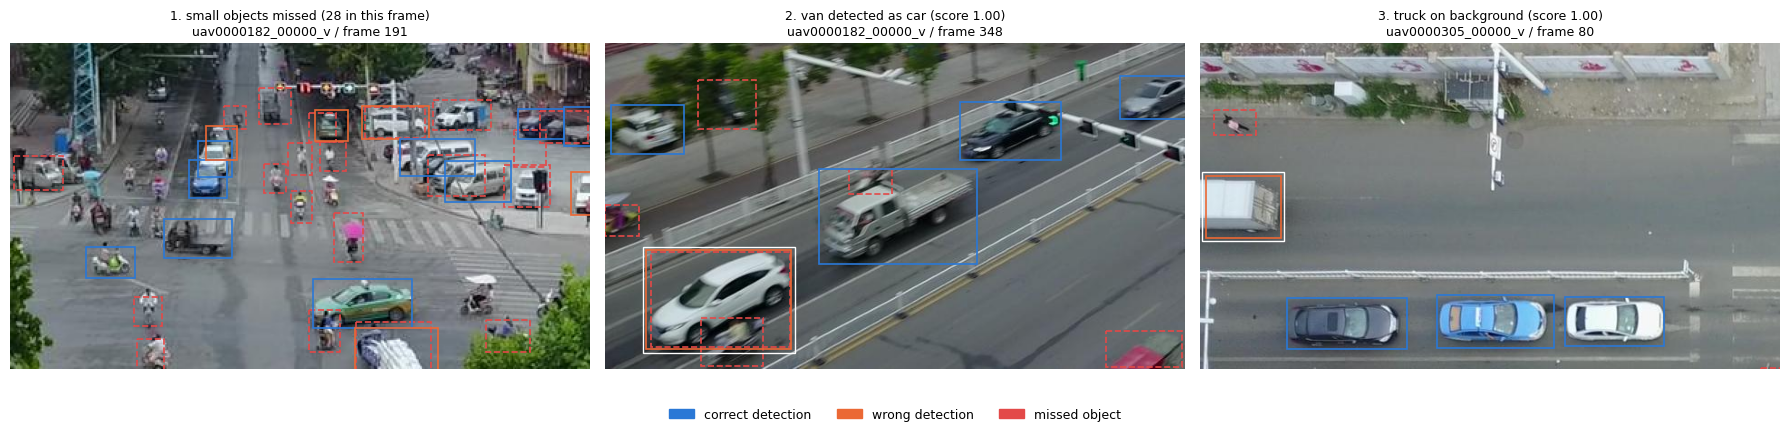

In [13]:
def panel(ax, image_id, center, title, focus=None, w=640, h=360):
    image = next(i for i in val_coco["images"] if i["id"] == image_id)
    x0 = int(np.clip(center[0] - w / 2, 0, image["width"] - w))
    y0 = int(np.clip(center[1] - h / 2, 0, image["height"] - h))
    ax.imshow(Image.open(DATA / "val" / image["file_name"]).crop((x0, y0, x0 + w, y0 + h)))
    here = errors[errors.image_id == image_id]
    for r in here[(here.kind == "object") & (here.score < THR)].itertuples():
        ax.add_patch(Rectangle((r.box[0] - x0, r.box[1] - y0), *(r.box[2:] - r.box[:2]), fill=False, color="#e34948", lw=1.2, ls="--"))
    for r in here[(here.kind != "object") & (here.score >= THR)].itertuples():
        color = "#2a78d6" if r.kind == "correct" else "#eb6834"
        ax.add_patch(Rectangle((r.box[0] - x0, r.box[1] - y0), *(r.box[2:] - r.box[:2]), fill=False, color=color, lw=1.2))
    if focus is not None:
        ax.add_patch(Rectangle((focus[0] - x0 - 4, focus[1] - y0 - 4), focus[2] - focus[0] + 8, focus[3] - focus[1] + 8, fill=False, color="white", lw=1))
    ax.set_title(f'{title}\n{image["video"]} / frame {image["frame_id"]}', fontsize=9)
    ax.axis("off")

small = missed[missed.area < 32 ** 2]
dense = small.image_id.value_counts().index[0]
centers = np.stack([(b[:2] + b[2:]) / 2 for b in small[small.image_id == dense].box])
near = (np.abs(centers[:, None] - centers[None]) < [200, 112]).all(2).sum(1)  # missed small objects inside a 400x225 crop
wrong = shown[shown.kind == "wrong class"].sort_values("score").iloc[-1]
background = shown[shown.kind == "background"].sort_values("score").iloc[-1]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
panel(axes[0], dense, centers[near.argmax()], f"1. small objects missed ({len(centers)} in this frame)", w=400, h=225)
panel(axes[1], wrong.image_id, (wrong.box[:2] + wrong.box[2:]) / 2,
      f"2. {names[wrong.truth]} detected as {names[wrong.cls]} (score {wrong.score:.2f})", wrong.box)
panel(axes[2], background.image_id, (background.box[:2] + background.box[2:]) / 2,
      f"3. {names[background.cls]} on background (score {background.score:.2f})", background.box)
fig.legend(handles=[Patch(color="#2a78d6", label="correct detection"), Patch(color="#eb6834", label="wrong detection"),
                    Patch(color="#e34948", label="missed object")], loc="lower center", ncol=3, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIGURES / "failure_cases.png", dpi=160)
plt.show()

## Final submissions

The two picks, both by validation: the best step overall, and the best step without the tiled Faster R-CNN (the newest member), so that one pick holds if that model does worse on test than on validation. The same fusion and rescoring are applied to the test predictions and written to `runs/local/submissions/`.

In [14]:
del val_dets, fused, final_val, errors
gc.collect()
picks = [BLEND, SECOND]
test_dets = {run: read_test(RUNS / run / "submission.csv") for name in picks for run in ENSEMBLES[name]}
for k, name in enumerate(picks, 1):
    write_submission(test, rescore(blend(ENSEMBLES[name], test_size, test_dets), test_clips, K, A), OUT / f"final_{k}.csv")
    step = f"{name} + temporal k={K} a={A}"
    print(f"final_{k}.csv: {step} (val mAP {table.set_index('step').mAP[step]:.4f}, public LB {LB.get(step)})")

final_1.csv: tile s x2 + tile m x2 + tile FRCNN x2 + 2 YOLO + 2 FRCNN + temporal k=2 a=0.2 (val mAP 0.3098, public LB 0.3073)


final_2.csv: tile s x2 + tile m x2 + 2 YOLO + 2 FRCNN + temporal k=2 a=0.2 (val mAP 0.3040, public LB 0.29206)
